# Test 2 - delay and delay variation with NetEm: analysis

Put this notebook next to the unpacked `T2` folder, or inside it with the data files:

```
T2/test2_delay_20261021T2350Z.csv
T2/export_pi5_127.0.0.1.jsonl.gz
T2/export_pi5_netmon-receiver.jsonl.gz
T2/export_vmagent_pi.jsonl.gz
T2/journal.txt.gz
```

Run all cells. Figures are shown here and saved to `figures/` as PDF (for LaTeX) and PNG.
The first 30 s of each step are left out so that no check overlaps a change of NetEm setting.

In [2]:
%matplotlib inline
import gzip, json, collections, math, os, glob, re, datetime as dt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

DATA = 'T2' if os.path.isdir('T2') else '.'
LOG = sorted(glob.glob(os.path.join(DATA, 'test2_delay_*.csv')))[-1]
print('data folder:', os.path.abspath(DATA)); print('test log   :', LOG)
OUT = 'figures'
os.makedirs(OUT, exist_ok=True)
EXCLUDE_MS = 30_000          # first 30 s of every step left out

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'font.size': 10, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'savefig.dpi': 300, 'figure.dpi': 120})
DARK_GREEN, BLACK, BLUE, GRAY = '#1b7a34', '#000000', '#2a78d6', '#8a8984'
GOOD, CRIT, ORANGE = '#0ca30c', '#e34948', '#c4511a'

def save(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(os.path.join(OUT, f'{name}.{ext}'), bbox_inches='tight')

def key(target, handles, labels, ncol=2, **kw):
    """Boxed legend with a bold 'Key' title (same look as Test 1)."""
    leg = target.legend(handles, labels, title='Key', title_fontproperties={'weight': 'bold', 'size': 9},
                        fontsize=8.5, ncol=ncol, frameon=True, edgecolor=BLACK, fancybox=False,
                        framealpha=1, **kw)
    leg.get_frame().set_linewidth(0.8)
    return leg

data folder: C:\Users\rich\OneDrive - University of Cape Town\1_FINAL_YEAR\EEE4022S Research Project\T2\T2
test log   : T2\test2_delay_20261021T2350Z.csv


## Load the test log and the exported data

In [3]:
def ms(s):
    return dt.datetime.fromisoformat(s.replace('Z', '+00:00')).timestamp() * 1000

# steps: (number, delay ms, jitter ms, start ms, end ms)
steps = []
for line in open(LOG):
    f = line.strip().split(',')
    if f[0].isdigit():
        steps.append((int(f[0]), int(f[1]), int(f[2]), ms(f[3]), ms(f[4])))

def load(fn):
    series = collections.defaultdict(list)
    for line in gzip.open(fn, 'rt'):
        o = json.loads(line)
        series[o['metric']['__name__']].append(o)
    return series

pi = load(os.path.join(DATA, 'export_pi5_127.0.0.1.jsonl.gz'))
rx = load(os.path.join(DATA, 'export_pi5_netmon-receiver.jsonl.gz'))
vm = load(os.path.join(DATA, 'export_vmagent_pi.jsonl.gz'))

def pts(src, name, s=0, e=float('inf'), **labels):
    out = []
    for o in src.get(name, []):
        if all(o['metric'].get(k) == v for k, v in labels.items()):
            out += [(t, v) for t, v in zip(o['timestamps'], o['values']) if v is not None and s <= t < e]
    return sorted(out)

T0 = steps[0][3]
end = steps[-1][4]
mins = lambda t: (t - T0) / 60000
label = lambda d, j: 'none' if d == 0 else (f'{d} ms' if j == 0 else f'{d} ± {j} ms')

# receiver send failures logged by vmagent (journal, UTC)
fails = []
for line in gzip.open(os.path.join(DATA, 'journal.txt.gz'), 'rt'):
    if "couldn't send" in line:
        fails.append(ms(line.split()[0]))
outages = []                                   # group failures less than 2 min apart
for t in fails:
    if outages and t - outages[-1][1] < 120_000:
        outages[-1][1] = t
    else:
        outages.append([t, t])

# iperf3 sets run by the scheduler during the test
iperf = pts(pi, 'iperf_test_active', T0, end)
steps

[(0, 0, 0, 1792626631000.0, 1792627231000.0),
 (1, 100, 0, 1792627231000.0, 1792627831000.0),
 (2, 100, 10, 1792627831000.0, 1792628431000.0),
 (3, 100, 25, 1792628431000.0, 1792629031000.0),
 (4, 100, 50, 1792629031000.0, 1792629631000.0),
 (5, 300, 0, 1792629631000.0, 1792630231000.0),
 (6, 1000, 0, 1792630231000.0, 1792630831000.0),
 (7, 2500, 0, 1792630831000.0, 1792631431000.0),
 (8, 0, 0, 1792631432000.0, 1792632032000.0)]

## Table 1 - results per step

In [4]:
rows = []
base = None
for n, d, j, s, e in steps:
    s2 = s + EXCLUDE_MS
    rtt = np.array([v for t, v in pts(pi, 'ping_rtt_ms', s2, e)])
    mdev = np.array([v for t, v in pts(pi, 'ping_rtt_mdev_ms', s2, e)])
    loss = pts(pi, 'ping_loss_pct', s2, e)
    state = pts(pi, 'monitor_backhaul_state', s2, e)
    snmp = pts(pi, 'snmp_status', s2, e)
    lost = sum(round(v / 20) for t, v in loss)
    r = dict(step=n, delay=d, jitter=j, t_start=mins(s), t_end=mins(e), checks=len(loss),
             rtt=rtt.mean(), mdev_med=np.median(mdev), mdev_q1=np.percentile(mdev, 25),
             mdev_q3=np.percentile(mdev, 75), mdevs=mdev,
             loss=lost / (5 * len(loss)) * 100, lost=lost,
             down=sum(v == 1 for t, v in state) / len(state) * 100,
             snmp_fail=sum(v == 2 for t, v in snmp) / len(snmp) * 100)
    if n == 0:
        base = r['rtt']
    r['added'] = r['rtt'] - base
    r['error'] = r['added'] - d
    rows.append(r)

head = ['Step', 'Time (min)', 'NetEm delay (ms)', 'Checks', 'Mean RTT (ms)', 'Added delay (ms)',
        'Error (ms)', 'Variation per check, median (IQR) (ms)', 'Ping loss (%)', 'Time reported down',
        'SNMP no reply']
lines = ['| ' + ' | '.join(head) + ' |', '|' + '---|' * len(head)]
for r in rows:
    err = '–' if r['delay'] == 0 else f"{r['error']:+.1f}"
    lines.append('| ' + ' | '.join([
        str(r['step']), f"{r['t_start']:.0f}–{r['t_end']:.0f}", label(r['delay'], r['jitter']),
        str(r['checks']), f"{r['rtt']:.1f}", f"{r['added']:.1f}", err,
        f"{r['mdev_med']:.1f} ({r['mdev_q1']:.1f}–{r['mdev_q3']:.1f})",
        f"{r['loss']:.2f} % ({r['lost']} ping{'' if r['lost'] == 1 else 's'})", f"{r['down']:.0f} %", f"{r['snmp_fail']:.0f} %"]) + ' |')
display(Markdown('\n'.join(lines)))
display(Markdown('*Added delay = mean RTT minus the step 0 mean RTT. Variation = ping mdev '
                 '(population standard deviation of the 5 RTTs in one check). IQR = middle 50 % of checks.*'))

import csv
with open(os.path.join(OUT, 't2_results_table.csv'), 'w', newline='') as f:
    w = csv.writer(f); w.writerow(head)
    for r in rows:
        w.writerow([r['step'], f"{r['t_start']:.0f}-{r['t_end']:.0f}", label(r['delay'], r['jitter']),
                    r['checks'], round(r['rtt'], 1), round(r['added'], 1), round(r['error'], 1),
                    round(r['mdev_med'], 1), round(r['loss'], 2), round(r['down'], 1), round(r['snmp_fail'], 1)])

| Step | Time (min) | NetEm delay (ms) | Checks | Mean RTT (ms) | Added delay (ms) | Error (ms) | Variation per check, median (IQR) (ms) | Ping loss (%) | Time reported down | SNMP no reply |
|---|---|---|---|---|---|---|---|---|---|---|
| 0 | 0–10 | none | 55 | 48.7 | 0.0 | – | 5.8 (4.1–7.7) | 0.00 % (0 pings) | 0 % | 0 % |
| 1 | 10–20 | 100 ms | 57 | 151.0 | 102.3 | +2.3 | 5.9 (4.4–7.9) | 0.00 % (0 pings) | 0 % | 0 % |
| 2 | 20–30 | 100 ± 10 ms | 57 | 149.1 | 100.4 | +0.4 | 8.0 (5.8–10.0) | 0.00 % (0 pings) | 0 % | 0 % |
| 3 | 30–40 | 100 ± 25 ms | 57 | 151.7 | 103.0 | +3.0 | 16.4 (11.1–19.8) | 0.35 % (1 ping) | 0 % | 0 % |
| 4 | 40–50 | 100 ± 50 ms | 57 | 152.6 | 103.9 | +3.9 | 28.7 (23.3–32.4) | 0.00 % (0 pings) | 0 % | 0 % |
| 5 | 50–60 | 300 ms | 57 | 346.5 | 297.8 | -2.2 | 4.4 (2.6–5.9) | 0.00 % (0 pings) | 0 % | 0 % |
| 6 | 60–70 | 1000 ms | 57 | 1046.9 | 998.2 | -1.8 | 5.0 (3.0–5.9) | 0.00 % (0 pings) | 0 % | 0 % |
| 7 | 70–80 | 2500 ms | 57 | 2547.1 | 2498.4 | -1.6 | 5.0 (3.4–6.3) | 0.70 % (2 pings) | 0 % | 0 % |
| 8 | 80–90 | none | 57 | 47.8 | -0.9 | – | 4.8 (3.2–7.2) | 1.75 % (5 pings) | 0 % | 0 % |

*Added delay = mean RTT minus the step 0 mean RTT. Variation = ping mdev (population standard deviation of the 5 RTTs in one check). IQR = middle 50 % of checks.*

## Figure 1 - measured against applied delay (fixed-delay steps)

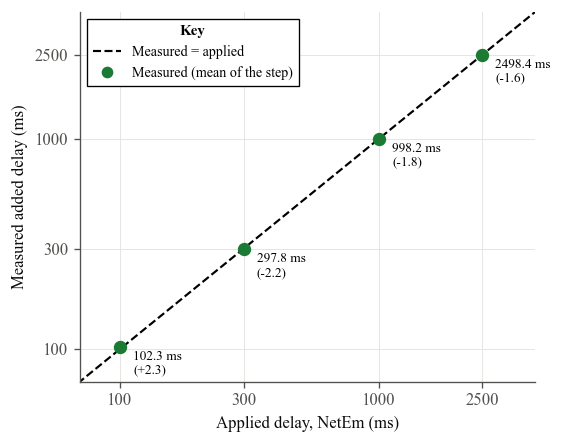

In [5]:
fixed = [r for r in rows if r['jitter'] == 0 and r['delay'] > 0]
fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.plot([50, 4000], [50, 4000], ls='--', lw=1.3, color=BLACK, zorder=1)
ax.plot([r['delay'] for r in fixed], [r['added'] for r in fixed], 'o', ms=7, color=DARK_GREEN, zorder=3)
for r in fixed:
    ax.annotate(f"{r['added']:.1f} ms\n({r['error']:+.1f})", (r['delay'], r['added']),
                xytext=(8, -16), textcoords='offset points', fontsize=8, color=BLACK)
ax.set_xscale('log'); ax.set_yscale('log')
ticks = [100, 300, 1000, 2500]
ax.set_xticks(ticks); ax.set_xticklabels(ticks); ax.set_yticks(ticks); ax.set_yticklabels(ticks)
ax.minorticks_off()
ax.set_xlim(70, 4000); ax.set_ylim(70, 4000)
ax.set_xlabel('Applied delay, NetEm (ms)'); ax.set_ylabel('Measured added delay (ms)')
key(ax, [Line2D([], [], color=BLACK, ls='--', lw=1.3), Line2D([], [], marker='o', ls='', color=DARK_GREEN, ms=6)],
    ['Measured = applied', 'Measured (mean of the step)'], ncol=1, loc='upper left')
fig.tight_layout(); save(fig, 't2_delay_measured_vs_applied'); plt.show()

## Figure 2 - measured variation against applied variation (steps 1-4)

NetEm spreads the delay **uniformly** between delay - jitter and delay + jitter when no distribution
is chosen (kernel `sch_netem.c`: "default uniform distribution"). The model below adds that uniform
spread to the LTE link's own noise (taken from the step 1 checks) and computes the mdev of 5 pings,
the same way the monitor does.

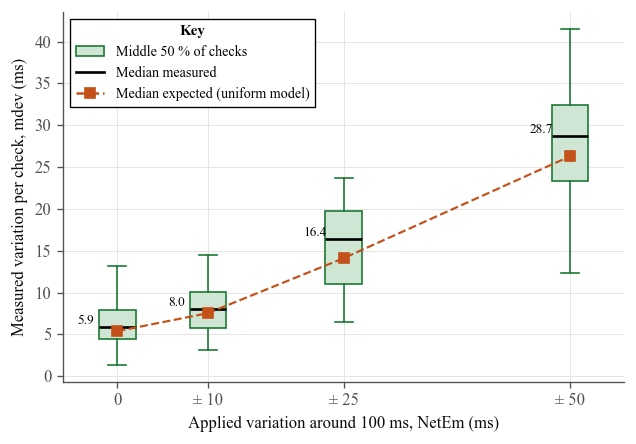

±  0 ms: measured median   5.9 ms, expected   5.4 ms (IQR measured 4.4-7.9, expected 3.5-8.3)
± 10 ms: measured median   8.0 ms, expected   7.5 ms (IQR measured 5.8-10.0, expected 5.6-10.3)
± 25 ms: measured median  16.4 ms, expected  14.1 ms (IQR measured 11.1-19.8, expected 11.0-17.5)
± 50 ms: measured median  28.7 ms, expected  26.3 ms (IQR measured 23.3-32.4, expected 20.8-31.8)


In [6]:
rng = np.random.default_rng(0)
jit = [r for r in rows if r['delay'] == 100]                 # steps 1-4 (100 ms base)
noise = jit[0]['mdevs']                                      # step 1: LTE noise only
def model(J, n=20000):
    sig = rng.choice(noise, n) * np.sqrt(5 / 4)              # population -> sample SD
    x = rng.normal(0, sig[:, None], (n, 5)) + rng.uniform(-J, J, (n, 5))
    return np.std(x, axis=1)                                 # population SD, like ping mdev
mod = {r['jitter']: model(r['jitter']) for r in jit}

fig, ax = plt.subplots(figsize=(5.4, 3.8))
pos = [r['jitter'] for r in jit]
bp = ax.boxplot([r['mdevs'] for r in jit], positions=pos, widths=4, showfliers=False,
                patch_artist=True, medianprops=dict(color=BLACK, lw=1.6),
                boxprops=dict(facecolor='#cfe6d4', edgecolor=DARK_GREEN),
                whiskerprops=dict(color=DARK_GREEN), capprops=dict(color=DARK_GREEN))
ax.plot(pos, [np.median(mod[J]) for J in pos], 's--', color=ORANGE, ms=6, lw=1.3, zorder=4)
for r in jit:
    ax.annotate(f"{r['mdev_med']:.1f}", (r['jitter'], r['mdev_med']), xytext=(-24, 2),
                textcoords='offset points', fontsize=8, color=BLACK)
ax.set_xticks(pos); ax.set_xticklabels([f'± {J}' if J else '0' for J in pos])
ax.set_xlim(-6, 56)
ax.set_xlabel('Applied variation around 100 ms, NetEm (ms)')
ax.set_ylabel('Measured variation per check, mdev (ms)')
key(ax, [Patch(facecolor='#cfe6d4', edgecolor=DARK_GREEN), Line2D([], [], color=BLACK, lw=1.6),
         Line2D([], [], color=ORANGE, marker='s', ls='--')],
    ['Middle 50 % of checks', 'Median measured', 'Median expected (uniform model)'], ncol=1, loc='upper left')
fig.tight_layout(); save(fig, 't2_variation_measured_vs_applied'); plt.show()

for r in jit:
    m = mod[r['jitter']]
    print(f"± {r['jitter']:>2} ms: measured median {r['mdev_med']:5.1f} ms, expected {np.median(m):5.1f} ms "
          f"(IQR measured {r['mdev_q1']:.1f}-{r['mdev_q3']:.1f}, expected {np.percentile(m, 25):.1f}-{np.percentile(m, 75):.1f})")

## Figure 3 - the test as a timeline

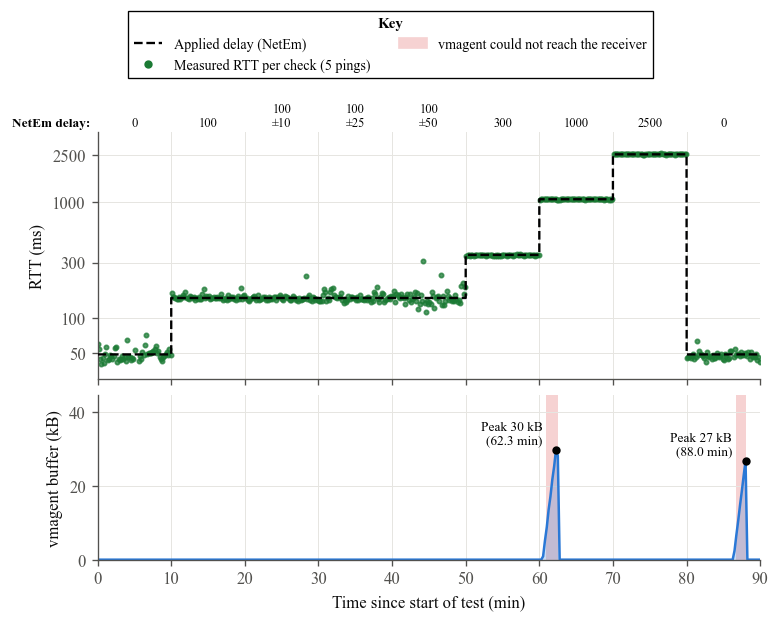

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(6.6, 5.2), sharex=True,
                        gridspec_kw={'height_ratios': [3, 2]})
# (a) RTT per check (log scale: 50 ms to 2.5 s) and the applied delay as one joined step line
rtt = pts(pi, 'ping_rtt_ms', T0, end)
axs[0].plot([mins(t) for t, v in rtt], [v for t, v in rtt], 'o', ms=2.6, color=DARK_GREEN, alpha=0.75)
sx, sy = [], []
for n, d, j, s, e in steps:
    sx += [mins(s), mins(e)]; sy += [base + d, base + d]
axs[0].plot(sx, sy, color=BLACK, lw=1.4, ls='--', zorder=3)
axs[0].set_yscale('log'); axs[0].set_ylim(30, 4000)
axs[0].set_yticks([50, 100, 300, 1000, 2500]); axs[0].set_yticklabels([50, 100, 300, 1000, 2500])
axs[0].minorticks_off()
axs[0].set_ylabel('RTT (ms)')
axs[0].text(-1, 1.01, 'NetEm delay:', ha='right', va='bottom', fontsize=8, fontweight='bold',
            transform=axs[0].get_xaxis_transform())
for n, d, j, s, e in steps:
    txt = '0' if d == 0 else (f'{d}' if j == 0 else f'{d}\n±{j}')
    axs[0].text(mins(s) + 5, 1.01, txt, ha='center', va='bottom', fontsize=7.5,
                transform=axs[0].get_xaxis_transform())
# (b) vmagent buffer + receiver send failures
pend = pts(vm, 'vmagent_remotewrite_pending_data_bytes', T0, end)
px, py = [mins(t) for t, v in pend], [v / 1000 for t, v in pend]
for a, b in outages:
    axs[1].axvspan(mins(a), mins(b) + 0.2, color='#f6d2d2', lw=0, zorder=0)
axs[1].fill_between(px, py, color=BLUE, alpha=0.25, lw=0)
axs[1].plot(px, py, color=BLUE, lw=1.5)
peaks, best = [], None
for x, y in zip(px, py):
    if y > 1:
        if best is None or y > best[1]: best = (x, y)
    elif best is not None:
        peaks.append(best); best = None
if best is not None: peaks.append(best)
for x, y in peaks:
    axs[1].plot(x, y, 'o', ms=4, color=BLACK, zorder=3)
    axs[1].annotate(f'Peak {y:.0f} kB\n({x:.1f} min)', (x, y), xytext=(-8, 2), textcoords='offset points',
                    ha='right', va='bottom', fontsize=8)
axs[1].set_ylim(0, max(py + [1]) * 1.5)
axs[1].set_ylabel('vmagent buffer (kB)'); axs[1].set_xlabel('Time since start of test (min)')
for ax in axs:
    for n, d, j, s, e in steps[1:]:
        ax.axvline(mins(s), color='#d4d3ce', lw=0.6, zorder=0)
h = [Line2D([], [], color=BLACK, ls='--', lw=1.4), Line2D([], [], marker='o', ls='', color=DARK_GREEN, ms=4),
     Patch(color='#f6d2d2')]
l = ['Applied delay (NetEm)', 'Measured RTT per check (5 pings)', 'vmagent could not reach the receiver']
key(fig, h, l, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.0))
axs[1].set_xlim(0, 90); axs[1].set_xticks(range(0, 91, 10))
fig.tight_layout(h_pad=0.6, rect=(0, 0, 1, 0.87)); save(fig, 't2_timeline'); plt.show()

## Delivery check - Pi against receiver

In [8]:
def samples(src):
    c = collections.Counter()
    for name, objs in src.items():
        for o in objs:
            k = tuple(sorted(o['metric'].items()))
            for t in o['timestamps']:
                c[(k, t)] += 1
    return c
a, b = samples(pi), samples(rx)
series = lambda src: sum(len(v) for v in src.values())
last = lambda name: (pts(vm, name) or [(0, 0)])[-1][1]
tab = [('Series', series(pi), series(rx)),
       ('Samples', sum(a.values()), sum(b.values())),
       ('Missing on receiver', '–', len(set(a) - set(b))),
       ('Extra on receiver', '–', len(set(b) - set(a))),
       ('Duplicates on receiver', '–', sum(n - 1 for n in b.values() if n > 1))]
lines = ['| | Pi | Receiver |', '|---|---|---|'] + [f'| {x} | {y} | {z} |' for x, y, z in tab]
display(Markdown('\n'.join(lines)))
dup_t = sorted({round(mins(t), 2) for (k, t), n in b.items() if n > 1})
print('duplicates at (min):', dup_t)
print('vmagent: retries', last('vmagent_remotewrite_retries_count_total'),
      '| packets dropped', last('vmagent_remotewrite_packets_dropped_total'),
      '| rate limit reached', last('vmagent_remotewrite_rate_limit_reached_total'))
for a_, b_ in outages:
    print(f'receiver not reachable: {mins(a_):.1f}-{mins(b_):.1f} min '
          f'({dt.datetime.fromtimestamp(a_ / 1000, dt.timezone.utc):%H:%M:%S}-'
          f'{dt.datetime.fromtimestamp(b_ / 1000, dt.timezone.utc):%H:%M:%S} UTC)')

| | Pi | Receiver |
|---|---|---|
| Series | 139 | 139 |
| Samples | 40630 | 40652 |
| Missing on receiver | – | 0 |
| Extra on receiver | – | 0 |
| Duplicates on receiver | – | 22 |

duplicates at (min): [60.25, 60.31, 60.35]
vmagent: retries 46 | packets dropped 0 | rate limit reached 0
receiver not reachable: 60.9-62.4 min (00:51:23-00:52:54 UTC)
receiver not reachable: 86.7-87.9 min (01:17:13-01:18:24 UTC)


## Delivery check - Pi against receiver

Compares every sample on the Pi with the copy on the laptop receiver (same series, same timestamp).

**Result:** 139 = 139 series, **0 missing**, 22 duplicates, 0 dropped by vmagent.

**Duplicates:** 22 samples (one round of ping, Wi-Fi, SNMP and state data measured at
00:50:45–00:50:52 UTC, step 6) are stored twice with identical series, timestamp and value.
vmagent sent the block, the reply did not return, and about 60 s later it logged
`Client.Timeout exceeded while awaiting headers` and sent the block again. This is
**at-least-once delivery**: vmagent resends when unsure, so it prefers a duplicate to a gap.

### Why it matters for the report

| Point | Meaning |
|---|---|
| **Strength** | No data loss in any outage so far: T0, Test 1 and Test 2 all have 0 missing. |
| **Limitation (GA 5)** | Duplicates can appear on the receiver. Plain averages are unaffected (same value twice), but anything that **counts** samples, such as `count_over_time`, counts them twice. |
| **Recommendation (Deliverable 6)** | VictoriaMetrics can remove duplicates when storing, with the `-dedup.minScrapeInterval` flag on the receiver. *(From memory of its docs – to be checked before use in the report.)* |

**One sentence for the report:** "The receiver held 22 duplicate samples (identical series,
timestamp and value) from one block that vmagent resent after a reply timeout; no samples were
missing, showing at-least-once delivery."

*To check before the report: the 60 s reply limit is assumed to be vmagent's default
`-remoteWrite.sendTimeout` (not shown in the logs).*